# 01 · NDWS exploratory data analysis and data-quality audit

Project 17: Next Day Wildfire Spread prediction, Phase 1 (ML).
Data: Kaggle *Next Day Wildfire Spread* (Huot et al., 2022). 18,545 patches of 64×64 km at 1 km, 11 environmental
inputs plus the day-t fire mask, and the target day t+1 fire mask.

Prerequisites: `python -m src.aml.ndws` (download + cache) and `python -m src.aml.splits`.
This notebook calls the functions in `src/aml/eda.py`; all figures are also written to `experiments/ndws/eda/`.

In [1]:
import os, sys, json
sys.path.insert(0, os.path.abspath('..'))
import numpy as np, pandas as pd
from IPython.display import Image, display, Markdown
pd.set_option('display.float_format', lambda v: f'{v:.4f}')
from src.aml import eda
from src.aml.ndws import load_split, CHANNELS
os.makedirs(eda.OUT_DIR, exist_ok=True)
{s: load_split(s).shape for s in ('train', 'eval', 'test')}

{'train': (14979, 13, 64, 64),
 'eval': (1877, 13, 64, 64),
 'test': (1689, 13, 64, 64)}

## 1. Class balance and label quality
Positive pixels (fire at t+1) are about 1% of known-label pixels, so accuracy is meaningless and PR-AUC is the primary metric.
Pixels with label −1 (cloud / missing) are excluded from training and evaluation.

split,train,eval,test
patches,14979.0000,1877.0000,1689.0000
pixels,61353984.0000,7688192.0000,6918144.0000
positive_rate,0.0110,0.0137,0.0125
unknown_label_rate,0.0235,0.0244,0.0275
prev_fire_rate,0.0082,0.0096,0.0094
prev_unknown_rate,0.0109,0.0140,0.0123
patches_without_next_day_fire,1706.0000,204.0000,202.0000
persistence_recall,0.2626,0.1866,0.2728
frac_next_day_fire_new,0.7374,0.8134,0.7272
frac_patches_growing,0.5817,0.5796,0.5903


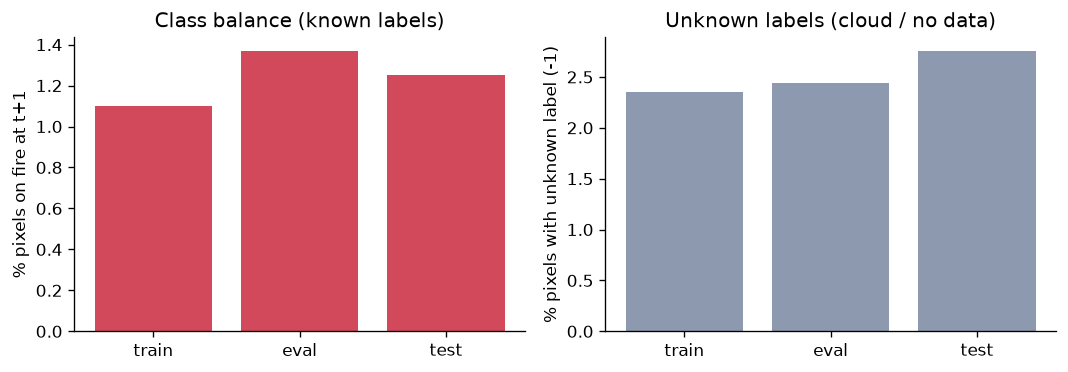

In [2]:
balance = eda.class_balance()
display(balance.set_index('split').T)
display(Image(os.path.join(eda.OUT_DIR, 'class_balance.png')))

**Observation:** only about 26% of next-day fire pixels were already burning at day t (`persistence_recall`), and about 74% are new.
Copying the day-t mask (persistence) therefore misses most of the target. The model has to predict *spread*.

## 2. Data-quality audit (sentinel and physically invalid values)

In [3]:
audit = pd.DataFrame(eda.quality_audit()).T
audit

,invalid_fraction,min,p1,median,p99,max
elevation,0.0000,-5.0000,0.0000,585.0000,2932.0000,4080.0000
th,0.0019,-496522.4375,29.1501,209.7591,332.2687,37620.3555
vs,0.0000,-2.6553,1.4183,3.4338,7.7831,14.7316
tmmn,0.0035,0.0000,264.9724,283.0945,296.5945,301.4086
tmmx,0.0035,0.0000,276.6897,299.8707,312.7240,344.3575
sph,0.0035,-0.0020,0.0011,0.0056,0.0175,0.0203
pr,0.0978,-7.3923,-0.0233,0.0000,6.5901,40.0105
NDVI,0.0000,-8882.0000,0.0000,5440.0000,8930.0000,9871.0000
population,0.0000,0.0000,0.0000,0.1647,868.0037,18580.7383
erc,0.0003,-0.2910,10.6261,48.1745,103.9027,298.4776


(`invalid_fraction` uses the physical ranges below; min/max come from a strided subsample.)
- `tmmn`, `tmmx` contain exact zeros (0 K: missing values) and maxima up to 344 K (71 °C, above any US record). Values outside 200–330 K become NaN.
- `sph` ≤ 0 and negative wind speeds `vs` become NaN.
- `th` (wind direction) contains corrupted values (down to about −5×10⁵). Values outside [0, 361] become NaN; (360, 361] is wrapped.
- Elevations slightly below 0 m are kept, because sub-sea-level terrain exists.
- `pr` has small negative values (interpolation artefacts), so it is clipped at 0.
- `NDVI` is stored ×10⁴, so it is rescaled. `population` is heavy-tailed, so we use log1p.

Cleaning lives in `src/aml/features.py::clean_channels` and is unit-tested.

## 3. Channel distributions: next-day fire vs no-fire pixels

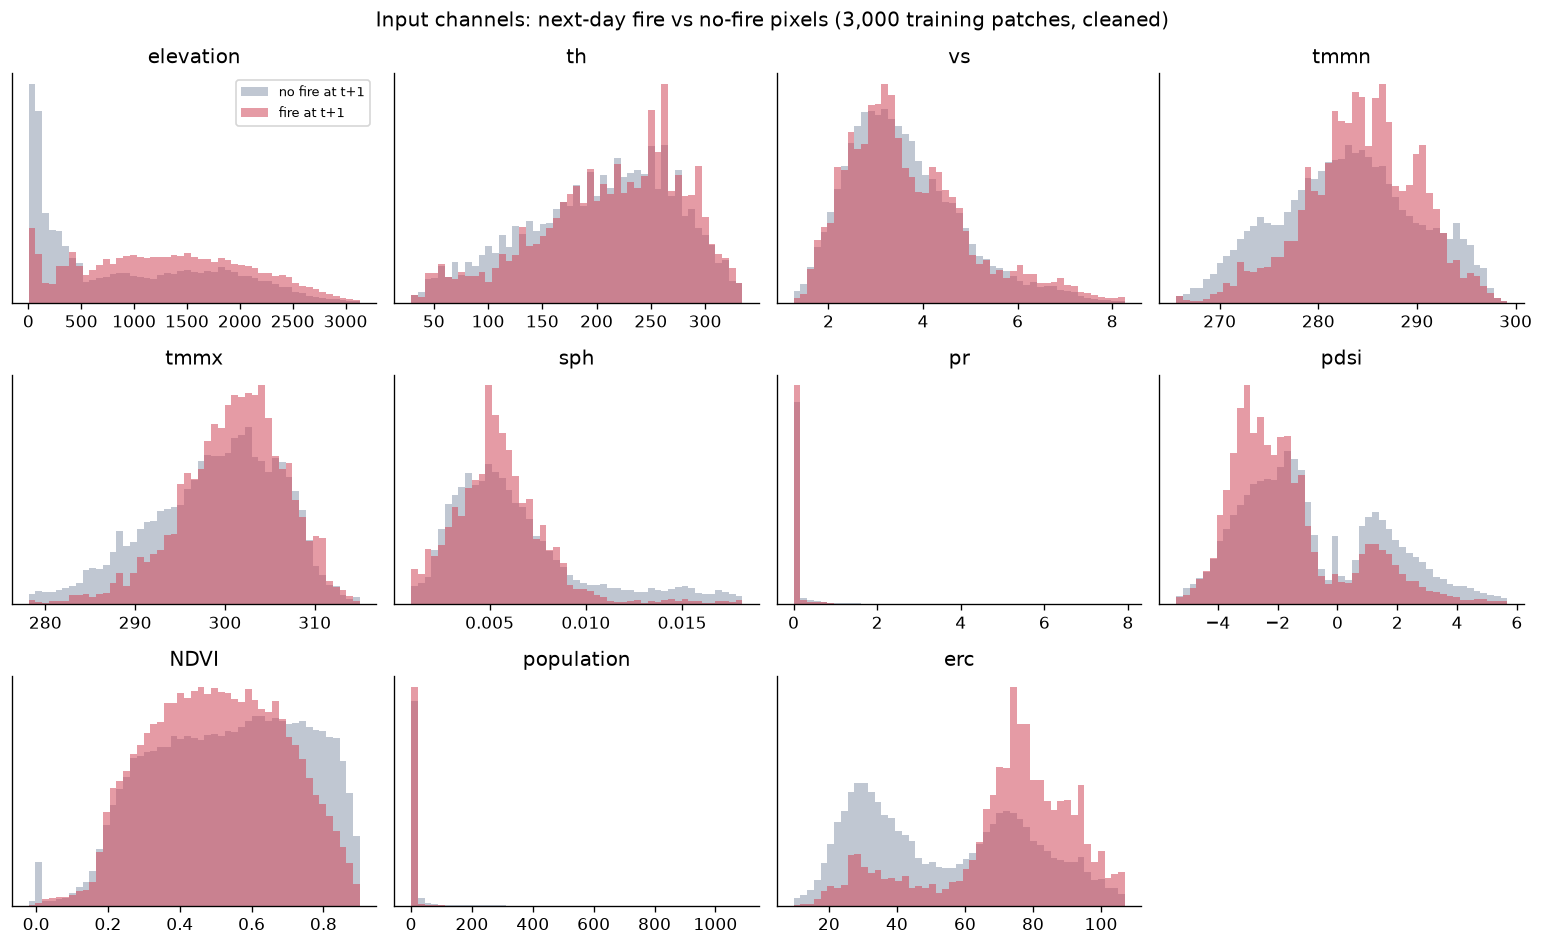

In [4]:
raw = eda.sample_patches()
eda.channel_distributions(raw)
display(Image(os.path.join(eda.OUT_DIR, 'channel_distributions.png')))

Next-day fire pixels have higher energy release component (most mass at ERC 70–90), drier drought index (PDSI < 0),
warmer minimum and maximum temperatures, fewer very-low-elevation (< 300 m) pixels and fewer densely vegetated pixels (NDVI > 0.75).
Wind speed, wind direction and precipitation barely differ. The distributions overlap heavily, so no single raw channel separates
the classes: these fields describe *conditions* (mostly constant across a patch), not *where* in the patch fire will appear.
The feature-group ablation in notebook 02 confirms that raw channels alone are weak.

## 4. Example patches

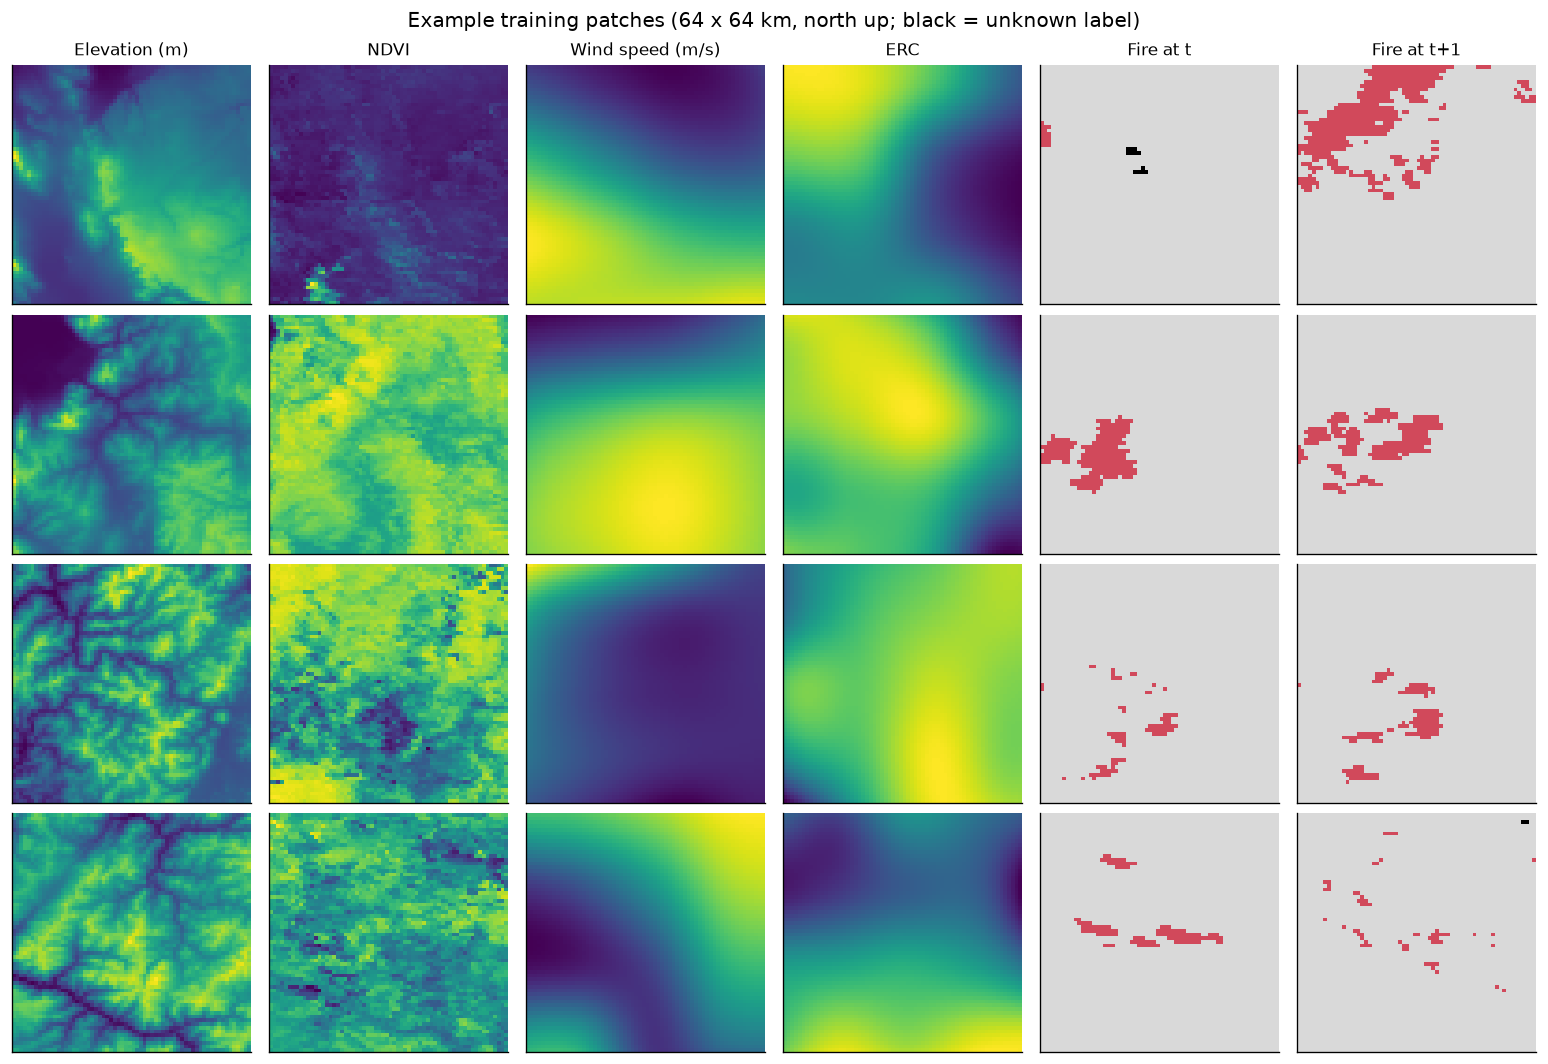

In [5]:
eda.example_patches(raw)
display(Image(os.path.join(eda.OUT_DIR, 'example_patches.png')))

## 5. Fire dynamics and distance to the front

{'stayed_burning': 0.34596385542168673, 'new_fraction_of_t1_fire': 0.7324377839034049}


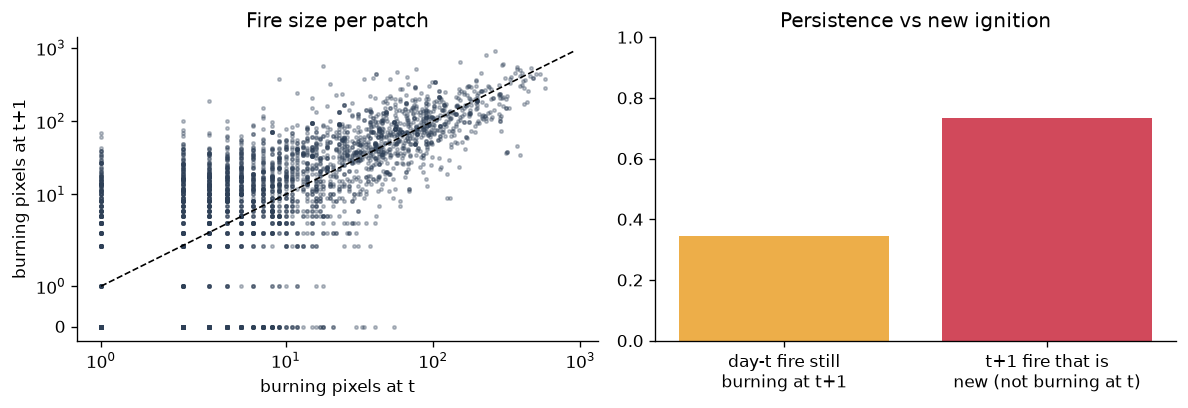

0-1.5     0.1961
1.5-2.5   0.1040
2.5-3.5   0.0633
3.5-5     0.0355
5-7       0.0180
7-10      0.0085
10-15     0.0041
15-25     0.0019
25-100    0.0010
Name: P(new fire), dtype: float64

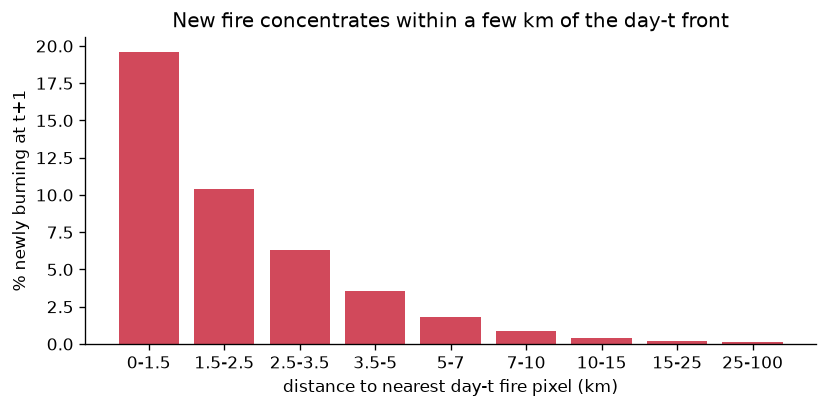

In [6]:
from src.aml.features import batch_features, FEATURES
from src.aml.ndws import CH
X = batch_features(raw).transpose(0, 2, 3, 1).reshape(-1, len(FEATURES))
y = raw[:, CH['FireMask']].reshape(-1)
print(eda.fire_dynamics(raw))
display(Image(os.path.join(eda.OUT_DIR, 'fire_dynamics.png')))
dist = eda.spread_vs_distance(X, y)
display(pd.Series(dist, name='P(new fire)'))
display(Image(os.path.join(eda.OUT_DIR, 'spread_vs_distance.png')))

New fire concentrates within a few km of the day-t front and decays quickly with distance. This motivates the
`dist_to_fire_km` and multi-scale `fire_frac_*` features.

## 6. Physical plausibility: wind and slope

The Kaggle release has no georeferencing, so the image orientation is unknown. We test both row conventions.
Physically, new fire should appear more often **downwind** of existing fire.

,p_new_fire_downwind_of_fire,p_new_fire_upwind_of_fire,ratio,ratio_ci95
"rows N->S, cols W->E",0.1565,0.1550,1.0099,"[0.982386, 1.040206]"
"rows S->N, cols W->E (adopted)",0.1679,0.1495,1.1230,"[1.094342, 1.153002]"
"rows N->S, cols E->W",0.1495,0.1679,0.8904,"[0.867301, 0.913791]"
"rows S->N, cols E->W",0.1550,0.1565,0.9902,"[0.961348, 1.017929]"


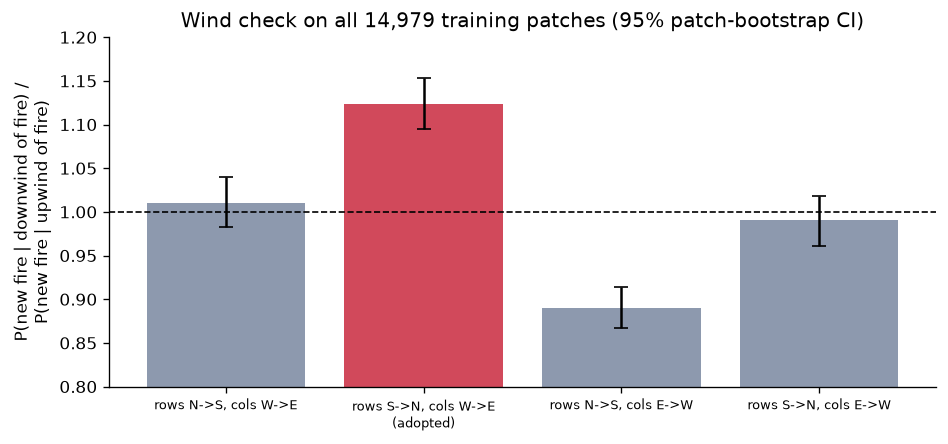

In [7]:
wind = eda.wind_orientation()  # all 14,979 training patches, about 1 min
display(pd.DataFrame(wind).T)
display(Image(os.path.join(eda.OUT_DIR, 'wind_orientation.png')))

Only rows south→north, columns west→east gives a downwind/upwind ratio significantly above 1 (about 1.12, CI excludes 1),
so it is adopted in `features.py`. The effect is modest because GRIDMET wind is a daily average at about 4 km.
Next, terrain near the fire:

{'downslope of fire': 0.16557784378528595, 'level': 0.07933752238750458, 'upslope of fire': 0.17008483409881592}


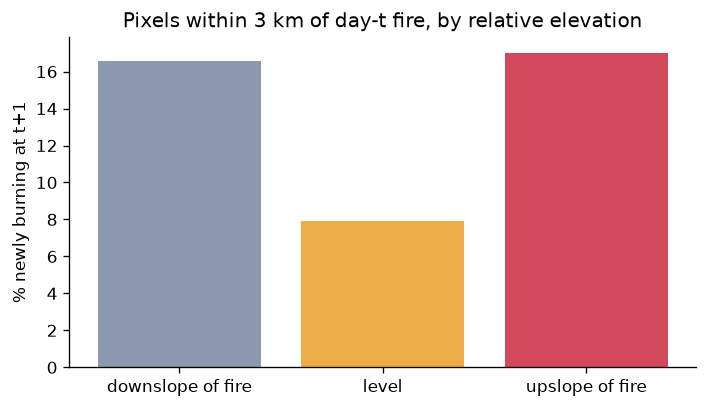

In [8]:
print(eda.terrain_effect(X, y))
display(Image(os.path.join(eda.OUT_DIR, 'terrain_effect.png')))

Pixels near fire on sloped ground (up- or downslope) burn about twice as often as level ground. The classic "fire runs upslope"
asymmetry is only marginal at 1 km / daily resolution, so slope magnitude matters more than direction here.

## 7. Engineered-feature correlation

tmmn ~ tmmx                       0.8977
tmmx ~ vpd_kpa                    0.9023
fire_wind_alignment ~ wind_push   0.9059
ndvi ~ ndvi_mean_5                0.9512
Name: Spearman rho, dtype: float64

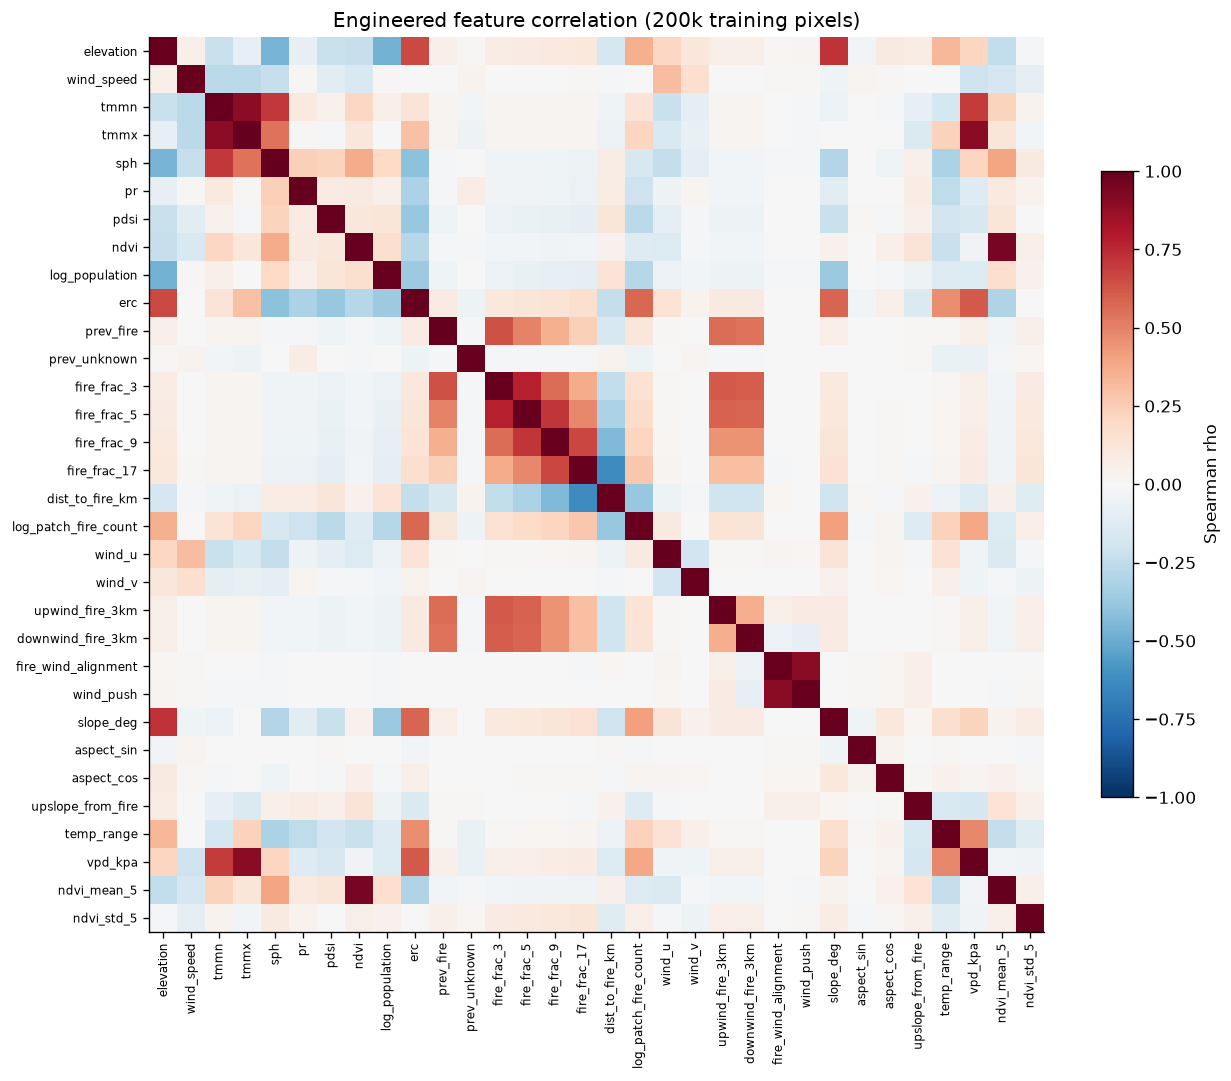

In [9]:
pairs = eda.feature_correlation(X[y >= 0])
display(pd.Series(pairs, name='Spearman rho'))
display(Image(os.path.join(eda.OUT_DIR, 'feature_correlation.png')))

Highly correlated pairs (e.g. tmin/tmax, the nested `fire_frac_*` windows) do not hurt tree models but inflate the
variance of logistic-regression coefficients. That is why LR coefficients are not interpreted causally and L2 regularisation is used.

## 8. Spatial leakage audit of the official split

Elevation is static, so an identical non-flat 8×8 km elevation block in two patches means they cover the same ground.
Mirrored patches (control) never match.

{
 "n_location_groups": 845,
 "largest_groups": [
  7246,
  5952,
  1320,
  721,
  261
 ],
 "mirrored_control_hits": "0 / 1855",
 "spatial_split_sizes": {
  "train": 14822,
  "test": 1868,
  "val": 1855
 }
}


,n_patches,share_terrain_with_train
eval,1877,1778
test,1689,1606
spatial_val,1855,0
spatial_test,1868,0


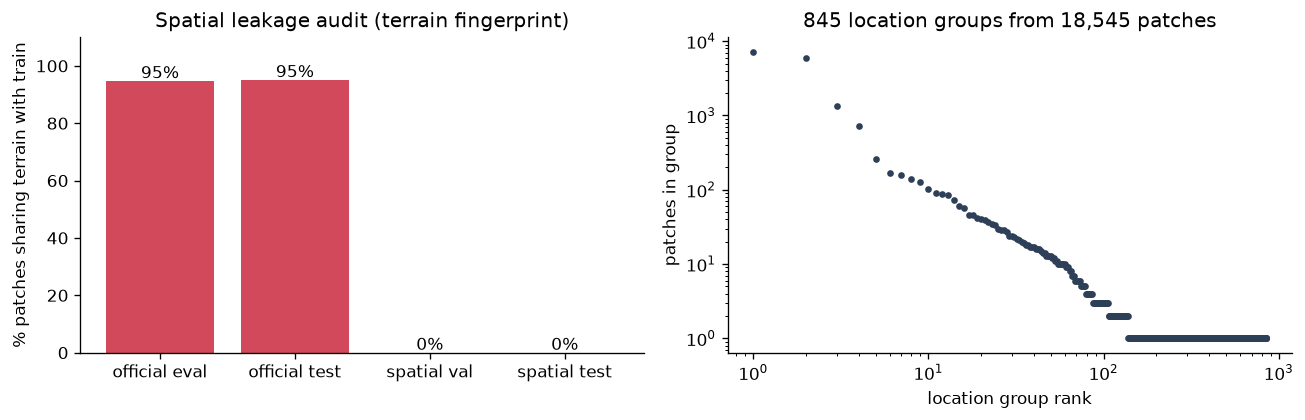

In [10]:
audit = eda.split_overlap()
print(json.dumps({k: audit[k] for k in ('n_location_groups', 'largest_groups', 'mirrored_control_hits', 'spatial_split_sizes')}, indent=1))
display(pd.DataFrame(audit['overlap']).T)
display(Image(os.path.join(eda.OUT_DIR, 'split_overlap.png')))

**About 95% of official test patches share terrain with official training patches.** The official split separates weeks, not
locations. We therefore evaluate on both the official split (comparable with the literature) and a location-grouped
spatial split (no shared terrain), as the brief asks: *separate events spatially and temporally*.